<a href="https://colab.research.google.com/github/OyeTaranpreet/AI-Applications-/blob/main/Laptop_Recommender_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Installing Libraries

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn flask flask-cors pyngrok joblib

## Importing Required Libraries

In [ ]:
import re
import io
import time
import base64
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, matthews_corrcoef, precision_score,
                             recall_score, f1_score, roc_auc_score, cohen_kappa_score, roc_curve,
                             make_scorer, mean_squared_error, r2_score)

# Classification algorithms (1.4A)
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier

# Regression algorithms (1.4B style)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## Ingesting the dataset

In [ ]:
df = pd.read_csv("/content/laptop_dataset_final-1.csv", low_memory=False)

df.head(10)

,Brand,Model,Series,Thickness,Dimensions (WxDxH),Weight,Colors,Operating System,Operating System Type,Display Size,...,Lockport,Battery Life,USB Type C,Battery Capacity,Aspect Ratio,Number of Cores,SSD Interface,Fast Charging Support,market_status,Price (Rs)
0,HP,14-dv0055TU (2N1L1PA),Pavilion,17 Millimeter thickness,325 x 216 x 17 mm,1.41 Kg weight (Light-weight),Tranquil Pink,Windows 10 Home Basic,64-bit,14 Inches (35.56 cm),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Available,71990.0
1,Acer,PHN16-71 (NH.QLTSI.002),Predator Helios Neo 16,26.5 Millimeter thickness,361 x 279 x 26.5 mm,2.6 Kg weight,Black,Windows 11 Home Basic,NaN,16 Inches (40.64 cm),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Available,105999.0
2,Dell,15 5570 (A560126WIN9),Inspiron 15,22.7 Millimeter thickness,380 x 258 x 22.7 mm,2.2 Kg weight,Platinum Silver,Windows 10 Home Basic,64-bit,15.6 Inches (39.62 cm),...,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Available,54999.0
3,MSI,GV62 7RD-2297XIN,NaN,29 Millimeter thickness,383 x 260 x 29 mm,2.2 Kg weight,Black,DOS,64-bit,15.6 Inches (39.62 cm),...,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Available,67990.0
4,Dell,15 3515 (D560702WIN9BE),Inspiron 15,23 Millimeter thickness,358.50 x 17.50 x 23 mm,1.8 Kg weight,"Carbon Black, Platinum Silver",Windows 11 Home Basic,64-bit,15.6 Inches (39.62 cm),...,NaN,7 Hrs,2.0,NaN,NaN,NaN,NaN,NaN,Available,42210.0
5,HP,15s-ey1004AU (38Z30PA),NaN,17.9 Millimeter thickness,358.5 x 242 x 17.9 mm,1.7 Kg weight,Natural Silver,Windows 10 Home Basic,64-bit,15.6 Inches (39.62 cm),...,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,Available,47990.0
6,Lenovo,(81WE0144IN),Ideapad Slim 3i,19.9 Millimeter thickness,362.2 x 253.4 x 19.9 mm,1.85 Kg weight,Grey,Windows 10 Home Basic,64-bit,15.6 Inches (39.62 cm),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Available,44990.0
7,iBall,CompBook Premio v3.0,NaN,24 Millimeter thickness,334 x 222 x 24 mm,1.3 Kg weight (Light-weight),Black,Windows 10 Home Basic,64-bit,14 Inches (35.56 cm),...,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Available,13990.0
8,Asus,14 OLED M3401QC-KM045WS,VivoBook Pro,19 Millimeter thickness,317 x 229 x 19 mm,1.45 Kg weight (Light-weight),Quiet Blue,Windows 11 Home Basic,NaN,14 Inches (35.56 cm),...,NaN,8 Hrs,NaN,63 WHrs,NaN,NaN,NaN,NaN,Available,89990.0
9,Asus,UX430UA-GV334T,Zenbook,15.9 Millimeter thickness (Slim),324 x 225 x 15.9 mm,1.25 Kg weight (Light-weight),Black,Windows 10 Professional,64-bit,14 Inches (35.56 cm),...,No,9 Hrs,NaN,NaN,NaN,NaN,NaN,NaN,Available,45990.0


## Exploring the dataset

In [ ]:
# Basic information: rows, columns, column names, data types and non-null counts.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8198 entries, 0 to 8197
Data columns (total 76 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Brand                       8198 non-null   object 
 1   Model                       8198 non-null   object 
 2   Series                      7105 non-null   object 
 3   Thickness                   7518 non-null   object 
 4   Dimensions (WxDxH)          7516 non-null   object 
 5   Weight                      7891 non-null   object 
 6   Colors                      8022 non-null   object 
 7   Operating System            8198 non-null   object 
 8   Operating System Type       4678 non-null   object 
 9   Display Size                8195 non-null   object 
 10  Display Resolution          8166 non-null   object 
 11  Pixel Density               8164 non-null   object 
 12  Display Type                4308 non-null   object 
 13  Display Features            8066 

In [ ]:
# Descriptive statistics for the columns that are already numeric.

df.describe()

,Wi-Fi Version,Bluetooth Version,USB 2.0 slots,Ethernet ports,USB 3.0 slots,USB Type C,Number of Cores,Price (Rs)
count,8124.000000,7380.000000,3225.000000,3444.000000,2223.000000,5191.000000,2925.000000,8177.000000
mean,5.454702,4.859404,1.328062,1.000581,1.692308,1.216336,8.917607,80852.045738
std,0.630616,0.475121,0.494043,0.024095,0.714243,0.450231,4.554171,59390.288254
min,4.000000,2.100000,1.000000,1.000000,1.000000,1.000000,2.000000,8990.000000
25%,5.000000,4.200000,1.000000,1.000000,1.000000,1.000000,6.000000,42490.000000
50%,5.000000,5.000000,1.000000,1.000000,2.000000,1.000000,8.000000,64989.000000
75%,6.000000,5.200000,2.000000,1.000000,2.000000,1.000000,12.000000,96990.000000
max,7.000000,6.000000,3.000000,2.000000,6.000000,4.000000,24.000000,499990.000000


In [ ]:
print("Size -->", df.shape)

# Print the number of rows (axis 0)
print("Rows  -->", df.shape[0])

# Print the number of columns (axis 1)
print("Columns -->", df.shape[1])

Size --> (8198, 76)
Rows  --> 8198
Columns --> 76


In [ ]:
# Missing values (only columns that have any, most missing first).

print("\nMissing Values")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False).head(25))


Missing Values
Fast Charging Support         7258
Thunderbolt Port              7205
Chipset                       7147
Aspect Ratio                  6869
Lockport                      6664
HDD Type                      6469
HDD Speed(RPM)                6462
HDD Capacity                  6344
SSD Interface                 6145
USB 3.0 slots                 5975
Brightness                    5826
SSD Type                      5744
Battery Capacity              5744
Face Recognition              5666
Other Networking Options      5660
Audio Solution                5562
Battery Life                  5476
Number of Cores               5273
Graphics Memory               5121
Refresh Rate                  5079
USB 2.0 slots                 4973
Secondary cam(Rear-facing)    4966
Expandable Memory             4963
Ethernet ports                4754
Sound Technologies            4565
dtype: int64


In [ ]:
print("Unique Values:\n")
print(df.nunique().sort_values().head(25))

Unique Values:

HDD Type                      1
Display Touchscreen           2
SSD Type                      2
Operating System Type         2
Headphone Jack                2
Face Recognition              2
VGA Port                      2
Battery Type                  2
SD Card Reader                2
Microphone Jack               2
In-built Microphone           2
Web-cam                       2
Bluetooth                     2
Ethernet ports                2
HDD Speed(RPM)                2
Secondary cam(Rear-facing)    2
Fast Charging Support         2
market_status                 2
Lockport                      2
Aspect Ratio                  3
USB 2.0 slots                 3
Wi-Fi Version                 4
SSD Interface                 4
USB Type C                    4
HDD Capacity                  5
dtype: int64


### Availability of listings`market_status` says whether a laptop can actually be bought. We recommend only **Available** laptops.

market_status
Available       5079
Out of Stock    3119
Name: count, dtype: int64


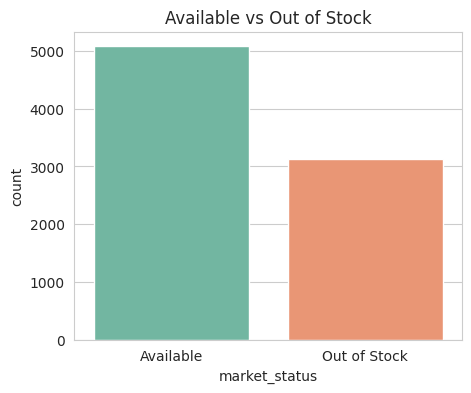

In [ ]:
print(df["market_status"].value_counts())

plt.figure(figsize=(5,4))
sns.countplot(x="market_status", data=df, palette="Set2")
plt.title("Available vs Out of Stock")
plt.show()

## Preparing numeric columnsMost columns are text (`"16 GB"`, `"2.3 Kg weight"`). This cell pulls the numbers out and turns the processor and graphics strings into simple 1 to 15 power tiers.

In [ ]:
def to_gb(s):
    # '16 GB' -> 16, '1 TB' -> 1024, '512' -> 512, blank -> 0
    s = str(s).strip()
    if s in ("", "nan"):
        return 0
    m = re.search(r"([\d.]+)", s)
    if not m:
        return 0
    n = float(m.group(1))
    if "TB" in s.upper():
        return n * 1024
    if "MB" in s.upper():
        return 0
    return n

def first_num(s):
    m = re.search(r"([\d.]+)", str(s))
    return float(m.group(1)) if m else np.nan

def gpu_tier(g):
    g = str(g)
    tiers = [(r"RTX 50(80|90)", 15), (r"RTX 40(80|90)", 13), (r"RTX 50(60|70)", 12), (r"RTX 4070", 10),
             (r"RTX 4060", 9), (r"RTX 30(70|80)", 9), (r"RTX 3060", 8), (r"RTX 4050", 7), (r"Radeon RX", 7),
             (r"RTX 3050|RTX 2050", 6), (r"RTX A\d|Quadro", 6), (r"GTX", 5), (r"Arc", 3), (r"Apple", 4),
             (r"Iris", 2), (r"Radeon", 1.5)]
    for pat, t in tiers:
        if re.search(pat, g, re.I):
            return t
    return 1

def cpu_tier(c):
    c = str(c)
    tiers = [(r"Ryzen 9|Core i9|Core Ultra 9|Apple M4", 5), (r"Ryzen 7|Core i7|Core Ultra 7|Apple M[23]", 4),
             (r"Apple M1", 3.5), (r"Ryzen 5|Core i5|Core Ultra 5", 3), (r"Ryzen 3|Core i3", 2),
             (r"Celeron|Pentium", 1)]
    for pat, t in tiers:
        if re.search(pat, c, re.I):
            return t
    return 2

df["RAM"]       = df["Capacity"].apply(to_gb)
df["SSD"]       = df["SSD Capacity"].apply(to_gb)
df["HDD"]       = df["HDD Capacity"].apply(to_gb)
df["VRAM"]      = df["Graphics Memory"].apply(to_gb)
df["Screen"]    = df["Display Size"].apply(first_num)
df["Weight"]    = df["Weight"].apply(first_num)
df["Thickness"] = df["Thickness"].apply(first_num)
df["Refresh"]   = df["Refresh Rate"].apply(first_num)
df["GPU_tier"]  = df["Graphic Processor"].apply(gpu_tier)
df["CPU_tier"]  = df["Processor"].apply(cpu_tier)
df["Price"]     = df["Price (Rs)"]

df[["Price", "RAM", "SSD", "HDD", "VRAM", "Screen", "Weight", "GPU_tier", "CPU_tier"]].describe()

,Price,RAM,SSD,HDD,VRAM,Screen,Weight,GPU_tier,CPU_tier
count,8177.000000,8198.000000,8198.000000,8198.000000,8198.000000,8195.000000,7891.000000,8198.000000,8198.000000
mean,80852.045738,12.119785,489.102952,230.079654,1.886192,15.012996,1.825335,2.886009,3.086058
std,59390.288254,7.571967,364.835439,436.719671,2.921377,1.054257,0.447875,2.613362,0.947573
min,8990.000000,2.000000,0.000000,0.000000,0.000000,10.100000,0.510000,1.000000,1.000000
25%,42490.000000,8.000000,256.000000,0.000000,0.000000,14.000000,1.500000,1.000000,2.000000
50%,64989.000000,8.000000,512.000000,0.000000,0.000000,15.600000,1.750000,1.500000,3.000000
75%,96990.000000,16.000000,512.000000,0.000000,4.000000,15.600000,2.190000,5.000000,4.000000
max,499990.000000,128.000000,4096.000000,2048.000000,24.000000,18.400000,5.500000,15.000000,5.000000


## Exploratory Data Analysis

### Histogram Plot

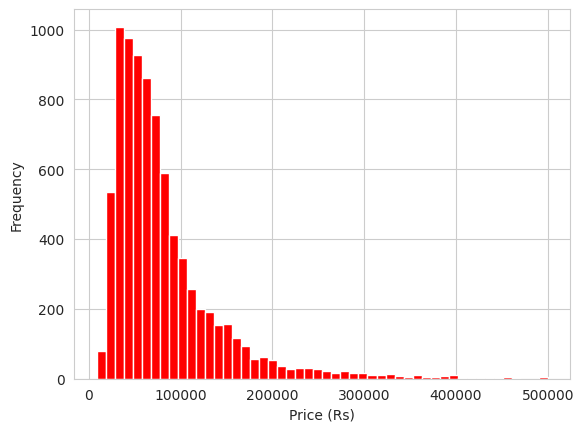

In [ ]:
#histogram plot

price = df['Price']

plt.xlabel('Price (Rs)')
plt.ylabel('Frequency')

plt.hist(price.dropna(), color = "red", bins=50)

plt.show()

### Boxplot for Outlier Detection

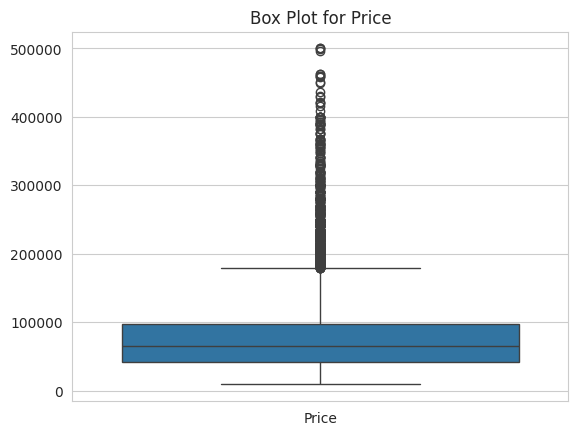

In [ ]:
sns.boxplot(data=df[["Price"]])

plt.title("Box Plot for Price")

plt.show()

### Correlation Matrix and Heatmap

In [ ]:
num_cols = ["Price", "RAM", "SSD", "HDD", "VRAM", "Screen", "Weight", "GPU_tier", "CPU_tier"]

df1 = df[num_cols].dropna()
df1.corr()

,Price,RAM,SSD,HDD,VRAM,Screen,Weight,GPU_tier,CPU_tier
Price,1.000000,0.756373,0.657565,-0.230818,0.626673,0.175688,0.289707,0.514898,0.683964
RAM,0.756373,1.000000,0.710134,-0.342852,0.506845,0.181664,0.195747,0.469267,0.633372
SSD,0.657565,0.710134,1.000000,-0.592691,0.498359,0.165837,0.141420,0.511573,0.604714
HDD,-0.230818,-0.342852,-0.592691,1.000000,-0.066347,0.147991,0.223199,-0.182158,-0.221672
VRAM,0.626673,0.506845,0.498359,-0.066347,1.000000,0.454766,0.636818,0.835406,0.553391
Screen,0.175688,0.181664,0.165837,0.147991,0.454766,1.000000,0.717668,0.405342,0.205883
Weight,0.289707,0.195747,0.141420,0.223199,0.636818,0.717668,1.000000,0.560622,0.262735
GPU_tier,0.514898,0.469267,0.511573,-0.182158,0.835406,0.405342,0.560622,1.000000,0.548169
CPU_tier,0.683964,0.633372,0.604714,-0.221672,0.553391,0.205883,0.262735,0.548169,1.000000


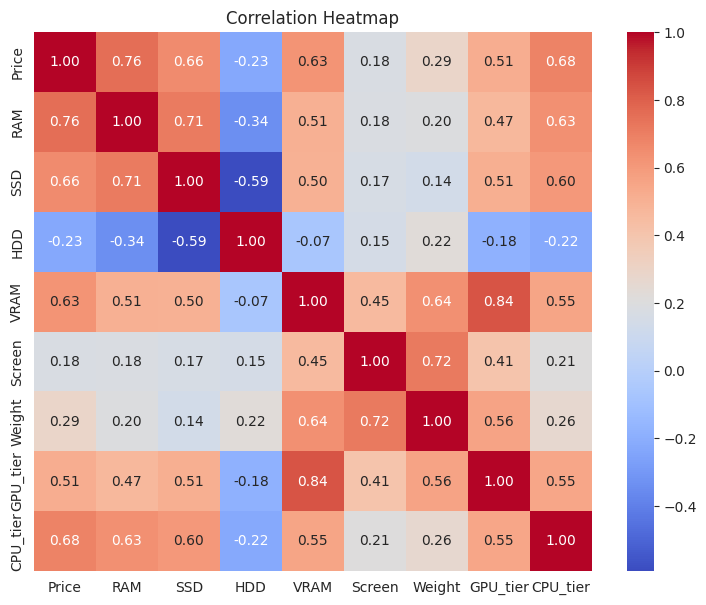

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(df1.corr(), annot=True, fmt=".2f", cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

### Scatter Plot

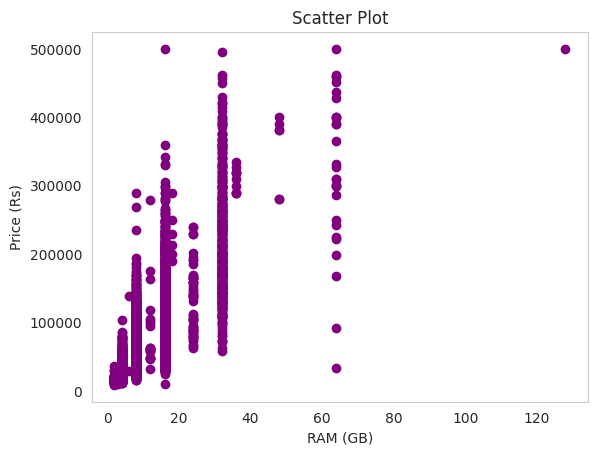

In [ ]:
plt.scatter(df['RAM'], df['Price'], color='purple')

plt.title("Scatter Plot")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (Rs)")

plt.grid()

plt.show()

### Which brands and operating systems are in the data?

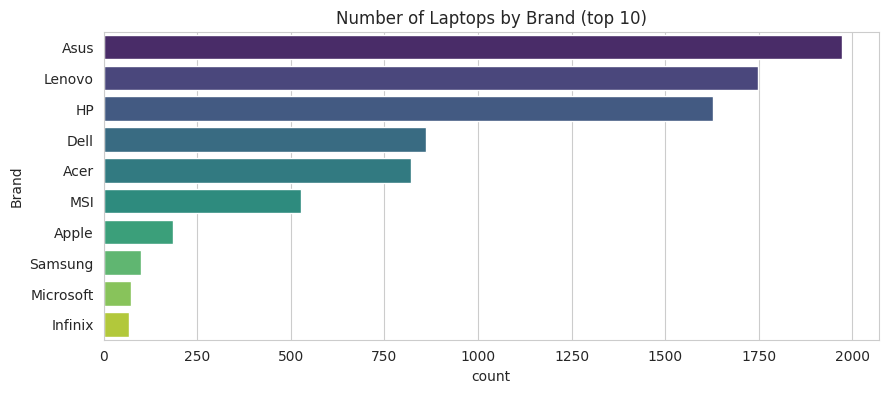

In [ ]:
top_brands = df["Brand"].value_counts().head(10).index

plt.figure(figsize=(10, 4))
sns.countplot(y="Brand", data=df[df["Brand"].isin(top_brands)], order=top_brands, palette="viridis")
plt.title("Number of Laptops by Brand (top 10)")
plt.show()

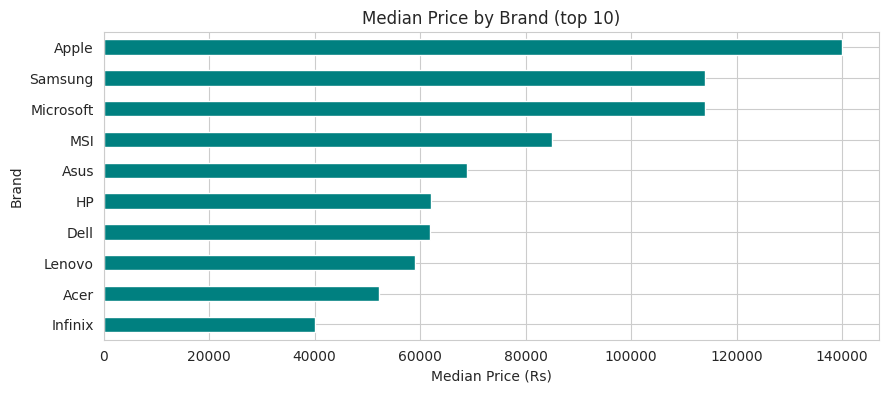

In [ ]:
med = df[df["Brand"].isin(top_brands)].groupby("Brand")["Price"].median().sort_values()

plt.figure(figsize=(10, 4))
med.plot(kind="barh", color="teal")
plt.title("Median Price by Brand (top 10)")
plt.xlabel("Median Price (Rs)")
plt.show()

### Advanced Exploratory Data Analysis
Let's implement advanced visualizations to understand brand pricing patterns, physical distributions, and multi-variable interactions.

In [ ]:
# 1. Price Distribution & Outlier Density for Top Brands
plt.figure(figsize=(12, 6))
sns.boxplot(x="Brand", y="Price", data=df[df["Brand"].isin(top_brands)],
            palette="Spectral", order=top_brands)
sns.stripplot(x="Brand", y="Price", data=df[df["Brand"].isin(top_brands)],
             order=top_brands, color="black", size=2, alpha=0.3, jitter=0.2)
plt.title("Price Ranges and Outlier Densities Across Top 10 Brands")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# 2. Joint Distribution of Portability Dimensions: Weight vs Thickness
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the target classification category column locally so the hue argument works
gaming_words = r"\b(ROG|TUF|Legion|LOQ|Predator|Nitro|Victus|Omen|Katana|Alienware|Helios|Thin GF|Raider|Gaming|Stealth|Blade|Pulse|Cyborg|Sword|Vector|Crosshair|Strix|Scar|Zephyrus|Aorus|Creator Z)\b"
name = df["Series"].astype(str) + " " + df["Model"].astype(str)
df["is_gaming"] = name.str.contains(gaming_words, case=False, regex=True).astype(int)

plt.figure(figsize=(10, 6))
sns.jointplot(x="Thickness", y="Weight", data=df, hue="is_gaming",
              kind="kde", palette="Set1", alpha=0.7, height=8)
plt.suptitle("Joint Density of Weight and Thickness (Everyday vs Gaming)", y=1.02)
plt.show()

In [ ]:
# 3. Spec Pairwise Interactions
pair_cols = ["Weight", "Refresh", "VRAM", "is_gaming"]
sns.pairplot(df[pair_cols].dropna(), hue="is_gaming", palette="husl", corner=True)
plt.suptitle("Pairwise Spec Intersections between Segment Classes", y=1.02)
plt.show()

## Creating the target label: Gaming or EverydayThe product line name (Series + Model) is used **only here** to create the label. It is not a model input.

In [ ]:
# Re-classify target labels into 3 classes: 0 = Everyday, 1 = Gaming, 2 = Business
# Parametric rules updated: any device with VRAM >= 4GB is strictly defined as Gaming (1)
gaming_words = r"\b(ROG|TUF|Legion|LOQ|Predator|Nitro|Victus|Omen|Katana|Alienware|Helios|Thin GF|Raider|Gaming|Stealth|Blade|Pulse|Cyborg|Sword|Vector|Crosshair|Strix|Scar|Zephyrus|Aorus|Creator Z)\b"

def classify_laptop(row):
    name = str(row["Series"]) + " " + str(row["Model"])
    is_gaming_name = bool(re.search(gaming_words, name, re.I))

    # Classify as Gaming based on name, high GPU Tier, high Refresh Rate, or at least 4GB VRAM
    if is_gaming_name or row["GPU_tier"] >= 6 or row["Refresh"] >= 120 or row["VRAM"] >= 4:
        return 1  # Gaming
    # Classify as Business if lightweight, standard components, and no gaming graphics (VRAM < 4)
    elif row["Weight"] <= 1.5 and row["GPU_tier"] < 6 and row["VRAM"] < 4:
        return 2  # Business
    else:
        return 0  # Everyday

df["laptop_class"] = df.apply(classify_laptop, axis=1)
print("Class distribution with VRAM updated rule:\n", df["laptop_class"].value_counts())

In [ ]:
# Rebuild features and fit the pipeline with updated multi-class logic
features = ["RAM", "SSD", "HDD", "VRAM", "Screen", "Weight", "Refresh", "GPU_tier", "CPU_tier"]

data = df[features + ["laptop_class"]].copy()
data["Refresh"] = data["Refresh"].fillna(60)
data = data.fillna(data.median(numeric_only=True))

X = data[features]
y = data["laptop_class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Train Random Forest Classifier
best_model = RandomForestClassifier(n_estimators=200, random_state=42)
best_model.fit(X_train_s, y_train)

y_pred = best_model.predict(X_test_s)
print("Evaluation of updated 3-class target system:\nAccuracy:", accuracy_score(y_test, y_pred))

In [ ]:
gaming_words = r"\b(ROG|TUF|Legion|LOQ|Predator|Nitro|Victus|Omen|Katana|Alienware|Helios|Thin GF|Raider|Gaming|Stealth|Blade|Pulse|Cyborg|Sword|Vector|Crosshair|Strix|Scar|Zephyrus|Aorus|Creator Z)\b"

name = df["Series"].astype(str) + " " + df["Model"].astype(str)
df["is_gaming"] = name.str.contains(gaming_words, case=False, regex=True).astype(int)

print(df["is_gaming"].value_counts())

plt.figure(figsize=(5, 4))
sns.countplot(x="is_gaming", data=df, palette="Set1")
plt.xticks([0, 1], ["Everyday", "Gaming"])
plt.title("Class Balance")
plt.show()

In [ ]:
# How do gaming laptops differ from everyday ones? Price and GPU tier.

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(x="is_gaming", y="Price", data=df, ax=ax[0], palette="Set2")
ax[0].set_xticklabels(["Everyday", "Gaming"])
ax[0].set_title("Price by Laptop Type")

sns.boxplot(x="is_gaming", y="GPU_tier", data=df, ax=ax[1], palette="Set2")
ax[1].set_xticklabels(["Everyday", "Gaming"])
ax[1].set_title("GPU Tier by Laptop Type")

plt.tight_layout()
plt.show()

# Machine Learning

### Separating Features and Target Variable

In [ ]:
# Specs only. No brand, series or model name goes into the model.

features = ["RAM", "SSD", "HDD", "VRAM", "Screen", "Weight", "Thickness", "Refresh", "GPU_tier", "CPU_tier"]

data = df[features + ["laptop_class"]].copy()

# A missing refresh rate is treated as a standard 60 Hz screen; other gaps get the column median.
data["Refresh"] = data["Refresh"].fillna(60)
data = data.fillna(data.median(numeric_only=True))

X = data[features]
y = data["laptop_class"]

### Splitting Dataset into Training and Testing Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Original Dataset Shape:", X.shape)
print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)
print()

print("Original Target Shape:", y.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape: ", y_test.shape)

### Feature Scaling Using StandardScaler

In [ ]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Baseline: Gaussian Naive Bayes (Experiment 1.3)

In [ ]:
model = GaussianNB()

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_scores = cross_val_score(model, X_train_s, y_train, cv=cv, scoring='accuracy')

print("Cross Validation Accuracy")
print(cv_scores)

print("Mean Accuracy :", cv_scores.mean())
print("Standard Deviation :", cv_scores.std())

model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Everyday", "Gaming", "Business"],
            yticklabels=["Everyday", "Gaming", "Business"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Naive Bayes Baseline)")
plt.show()

In [ ]:
# Calculate multi-class metrics using macro averaging for Naive Bayes baseline
y_prob_all = model.predict_proba(X_test_s) # Get probabilities for all 3 classes

results = pd.DataFrame({
    "Metric": ["Accuracy", "Kappa", "Precision (Macro)", "Recall (Macro)", "F1 Score (Macro)", "ROC-AUC (OVR)", "MCC"],
    "Value": [
        accuracy_score(y_test, y_pred),
        cohen_kappa_score(y_test, y_pred),
        precision_score(y_test, y_pred, average='macro'),
        recall_score(y_test, y_pred, average='macro'),
        f1_score(y_test, y_pred, average='macro'),
        roc_auc_score(y_test, y_prob_all, multi_class='ovr'),
        matthews_corrcoef(y_test, y_pred)
    ]
})

print(results.round(4))

## Comparing 13 classification algorithms (Experiment 1.4A)

In [ ]:
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef, cohen_kappa_score
import time

# Configure models for evaluation
models = {
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Ridge Classifier": RidgeClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "K Nearest Neighbor": KNeighborsClassifier(),
    "SVM": SVC(probability=True),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),
    "Quadratic Discriminant Analysis": QuadraticDiscriminantAnalysis(),
    "Dummy Classifier": DummyClassifier(strategy="most_frequent")
}

# Define scorers that do not require predict_proba
scoring_base = {
    "Accuracy": "accuracy",
    "Recall": make_scorer(recall_score, average='macro'),
    "Precision": make_scorer(precision_score, average='macro'),
    "F1": make_scorer(f1_score, average='macro'),
    "Kappa": make_scorer(cohen_kappa_score),
    "MCC": make_scorer(matthews_corrcoef)
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

results = []

for name, m in models.items():
    start = time.time()

    # Combine base scorers with the appropriate AUC scorer only if predict_proba is supported
    current_scoring = scoring_base.copy()
    if hasattr(m, "predict_proba") or (hasattr(m, "probability") and getattr(m, "probability")):
        current_scoring["AUC"] = make_scorer(roc_auc_score, multi_class='ovr', response_method='predict_proba')
    else:
        auc_scorer = None

    scores = cross_validate(m, X_train_s, y_train, cv=cv, scoring=current_scoring, error_score="raise")
    end = time.time()

    results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "AUC": scores["test_AUC"].mean() if "test_AUC" in scores else np.nan,
        "Recall": scores["test_Recall"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "F1 Score": scores["test_F1"].mean(),
        "Kappa": scores["test_Kappa"].mean(),
        "MCC": scores["test_MCC"].mean(),
        "TT (Sec)": end - start
    })

In [ ]:
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(by="F1 Score", ascending=False)
comparison.reset_index(drop=True, inplace=True)
comparison = comparison.round(4)

print("\nModel Comparison")
display(comparison)


Model Comparison


,Model,Accuracy,AUC,Recall,Precision,F1 Score,Kappa,MCC,TT (Sec)
0,Gradient Boosting,0.9982,0.9995,0.9983,0.9983,0.9983,0.9972,0.9972,17.7295
1,Decision Tree,0.9980,0.9986,0.9983,0.9981,0.9982,0.9969,0.9969,0.5044
2,Random Forest,0.9979,0.9998,0.9981,0.9980,0.9980,0.9967,0.9967,3.7712
3,Extra Trees,0.9922,0.9997,0.9910,0.9923,0.9916,0.9879,0.9879,5.0578
4,SVM,0.9837,0.9989,0.9835,0.9817,0.9826,0.9747,0.9747,21.7416
5,Logistic Regression,0.9831,0.9981,0.9828,0.9805,0.9816,0.9738,0.9738,2.3605
6,AdaBoost,0.9822,0.9944,0.9830,0.9802,0.9810,0.9723,0.9729,2.3996
7,K Nearest Neighbor,0.9674,0.9925,0.9633,0.9654,0.9643,0.9493,0.9494,1.8816
8,Quadratic Discriminant Analysis,0.9358,0.9774,0.9215,0.9337,0.9265,0.8998,0.9005,0.2900
9,Naive Bayes,0.9253,0.9797,0.9188,0.9155,0.9167,0.8843,0.8848,0.4241


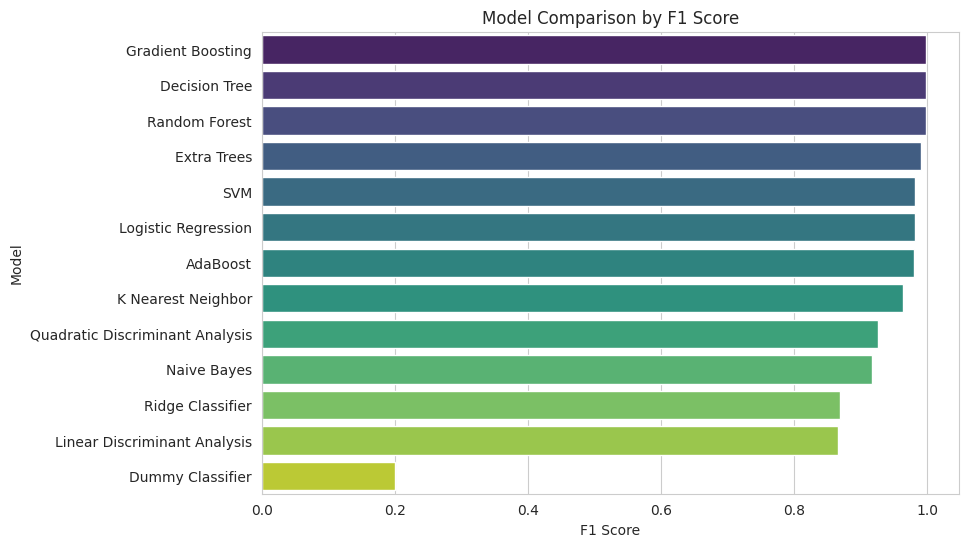

In [ ]:
plt.figure(figsize=(9, 6))
sns.barplot(x="F1 Score", y="Model", data=comparison, palette="viridis")
plt.title("Model Comparison by F1 Score")
plt.show()

## Model parametersTune the best model (Random Forest) with a small grid search, then look at what it learned.

In [ ]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Best parameters :", grid.best_params_)
print("Best CV Accuracy  :", round(grid.best_score_, 4))

best_model = grid.best_estimator_

Best parameters : {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 100}
Best CV Accuracy  : 0.9977


In [ ]:
# Final evaluation of the tuned Random Forest model on the unseen test set using multi-class metrics
y_pred = best_model.predict(X_test_s)
y_prob_all = best_model.predict_proba(X_test_s) # Full probabilities for all 3 classes

final = pd.DataFrame({
    "Metric": ["Accuracy", "Kappa", "Precision (Macro)", "Recall (Macro)", "F1 Score (Macro)", "ROC-AUC (OVR)", "MCC"],
    "Value": [
        accuracy_score(y_test, y_pred),
        cohen_kappa_score(y_test, y_pred),
        precision_score(y_test, y_pred, average='macro'),
        recall_score(y_test, y_pred, average='macro'),
        f1_score(y_test, y_pred, average='macro'),
        roc_auc_score(y_test, y_prob_all, multi_class='ovr'),
        matthews_corrcoef(y_test, y_pred)
    ]
}).round(4)

print(final)

              Metric   Value
0           Accuracy  0.9988
1              Kappa  0.9981
2  Precision (Macro)  0.9991
3     Recall (Macro)  0.9988
4   F1 Score (Macro)  0.9989
5      ROC-AUC (OVR)  1.0000
6                MCC  0.9981


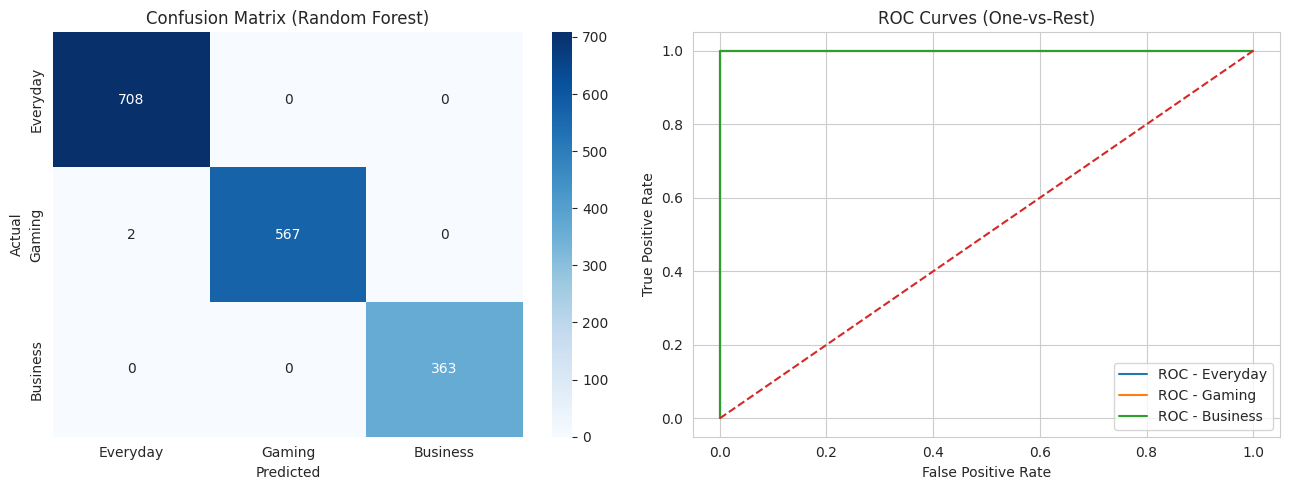

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Multi-class confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Everyday", "Gaming", "Business"],
            yticklabels=["Everyday", "Gaming", "Business"])
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")
ax[0].set_title("Confusion Matrix (Random Forest)")

# One-vs-Rest ROC curves for each class
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
classes_names = ["Everyday", "Gaming", "Business"]

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_all[:, i])
    ax[1].plot(fpr, tpr, label=f"ROC - {classes_names[i]}")

ax[1].plot([0, 1], [0, 1], "--")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curves (One-vs-Rest)")
ax[1].legend()

plt.tight_layout()
plt.show()

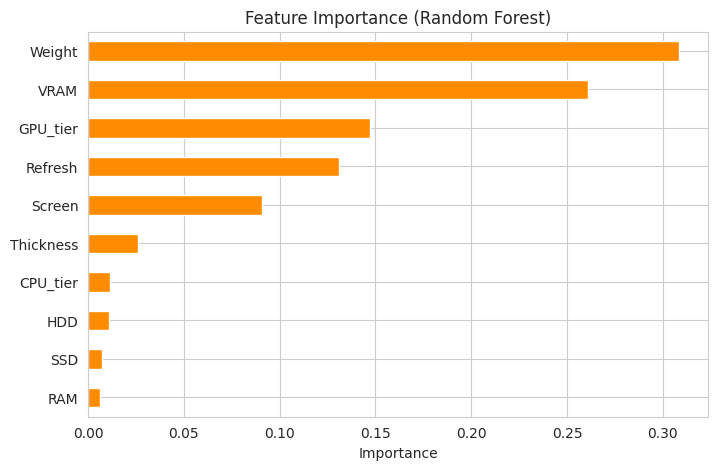

Weight       0.3082
VRAM         0.2608
GPU_tier     0.1472
Refresh      0.1309
Screen       0.0910
Thickness    0.0263
CPU_tier     0.0116
HDD          0.0107
SSD          0.0073
RAM          0.0060
dtype: float64


In [ ]:
# Which specs matter most to the model?

importance = pd.Series(best_model.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="darkorange")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

print(importance.sort_values(ascending=False).round(4))

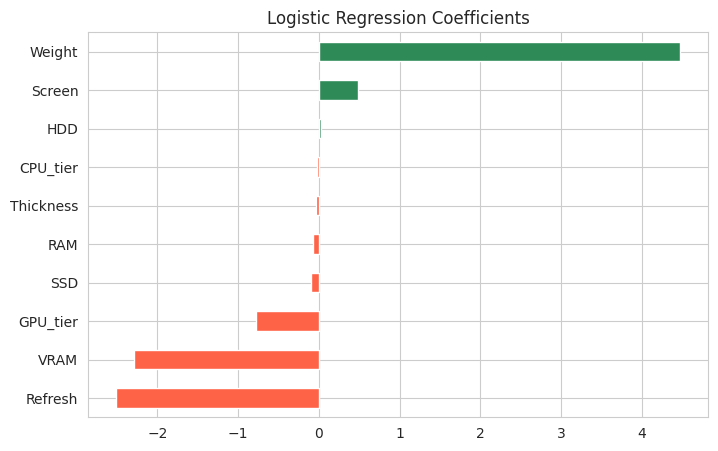

Intercept: 2.4753
Refresh     -2.5099
VRAM        -2.2932
GPU_tier    -0.7741
SSD         -0.0959
RAM         -0.0683
Thickness   -0.0304
CPU_tier    -0.0223
HDD          0.0203
Screen       0.4801
Weight       4.4726
dtype: float64


In [ ]:
# Logistic Regression coefficients: positive pushes toward Gaming, negative toward Everyday (features are scaled, so sizes are comparable).

lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)

coef = pd.Series(lr.coef_[0], index=features).sort_values()

plt.figure(figsize=(8, 5))
coef.plot(kind="barh", color=["tomato" if v < 0 else "seagreen" for v in coef])
plt.title("Logistic Regression Coefficients")
plt.show()

print("Intercept:", round(lr.intercept_[0], 4))
print(coef.round(4))

## Price side-model: regression comparison (Experiment 1.4B style)Price is no longer the point of the project, but a regression still shows how well specs explain price.

In [ ]:
reg_features = ["RAM", "SSD", "HDD", "VRAM", "Screen", "Weight", "GPU_tier", "CPU_tier"]

reg = df[reg_features + ["Price"]].copy()
reg = reg.dropna(subset=["Price"])
reg = reg.fillna(reg.median(numeric_only=True))

Xr = reg[reg_features]
yr = reg["Price"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.20, random_state=42)

reg_scaler = StandardScaler()
Xr_train_s = reg_scaler.fit_transform(Xr_train)
Xr_test_s = reg_scaler.transform(Xr_test)

reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

rows = []
for name, m in reg_models.items():
    m.fit(Xr_train_s, yr_train)
    p = m.predict(Xr_test_s)
    rows.append({"Model": name, "RMSE (Rs)": np.sqrt(mean_squared_error(yr_test, p)), "R2": r2_score(yr_test, p)})

reg_results = pd.DataFrame(rows).sort_values("R2", ascending=False).round(3).reset_index(drop=True)
display(reg_results)

,Model,RMSE (Rs),R2
0,Random Forest,23408.319,0.847
1,Gradient Boosting,24617.213,0.831
2,Decision Tree,27484.107,0.789
3,Linear Regression,30808.588,0.735
4,Lasso,30808.847,0.735
5,Ridge,30809.221,0.735


## The recommenderThe tuned classifier gives every laptop a **fit score** (the probability it is a gaming laptop). Recommendations are real laptops that are **Available** and inside the budget, ranked by that score.

In [ ]:
# Score every laptop. cross_val_predict gives each laptop a score from a model that did NOT see it in training,
# so the scores are not inflated the way they would be if we scored the training rows directly.

from sklearn.model_selection import cross_val_predict

all_scaled = scaler.transform(data[features])
df["gaming_score"] = cross_val_predict(best_model, all_scaled, y, cv=5, method="predict_proba")[:, 1]

available = df[df["market_status"] == "Available"].copy()
print("Laptops we can recommend:", len(available))

Laptops we can recommend: 5079


In [ ]:
def recommend(min_price, max_price, need="gaming", top_n=5):
    # need = "gaming"   -> highest gaming_score first
    # need = "everyday" -> lowest gaming_score first (lighter laptops win ties)
    pool = available[(available["Price"] >= min_price) & (available["Price"] <= max_price)].copy()

    if need == "gaming":
        pool = pool.sort_values("gaming_score", ascending=False)
    else:
        pool["everyday_score"] = 1 - pool["gaming_score"]
        pool = pool.sort_values(["everyday_score", "Weight"], ascending=[False, True])

    cols = ["Brand", "Series", "Model", "Processor", "RAM", "SSD", "Graphic Processor", "Screen", "Price", "gaming_score"]
    return pool[cols].head(top_n).reset_index(drop=True)

print("Top gaming laptops between Rs 70,000 and Rs 1,00,000")
display(recommend(70000, 100000, "gaming"))

print("Top everyday laptops under Rs 50,000")
display(recommend(0, 50000, "everyday"))

Top gaming laptops between Rs 70,000 and Rs 1,00,000


,Brand,Series,Model,Processor,RAM,SSD,Graphic Processor,Screen,Price,gaming_score
0,Acer,Nitro 5,AN515-58 (NH.QFHSI.008),Intel Core i5-12450H (12th Gen),8.0,512.0,NVIDIA Geforce RTX 3050,15.6,77425.0,1.0
1,Asus,Gaming V16,V3607VU-RP275WS,Intel Core 7 - 240H (Series 2),16.0,512.0,NVIDIA GeForce RTX 4050,16.0,89990.0,1.0
2,MSI,Thin 15,B12UC-2240IN,Intel Core i7 - 12650H (12th Gen),16.0,512.0,NVIDIA GeForce RTX 3050,15.6,77211.0,1.0
3,Asus,VivoBook Pro,14 OLED M3401QC-KM045WS,AMD Octa Core Ryzen 7-5800H,16.0,512.0,NVIDIA GeForce RTX 3050,14.0,89990.0,1.0
4,MSI,Thin 15,B12UC-2239IN,Intel Core i7 - 12650H (12th Gen),16.0,1024.0,NVIDIA GeForce RTX 3050,15.6,70211.0,1.0


Top everyday laptops under Rs 50,000


,Brand,Series,Model,Processor,RAM,SSD,Graphic Processor,Screen,Price,gaming_score
0,Reliance,NaN,JioBook (NB1112MM),Mediatek MT8788,4.0,0.0,MediaTek Integrated,11.6,16499.0,0.0
1,iBall,NaN,CompBook Merit G9,Intel Celeron Dual Core N3350,2.0,32.0,Intel HD Graphics,11.6,9990.0,0.0
2,Lenovo,Ideapad,3 CB 11IGL05 (82BA001PHA),Intel Celeron Dual Core N4020,4.0,64.0,Intel UHD,11.6,18990.0,0.0
3,Lenovo,Ideapad,1 11IGL05 (81VT0071IN),Intel Celeron Dual Core N4020,4.0,256.0,Intel UHD,11.6,23999.0,0.0
4,Lenovo,Ideapad,1 11IGL05 (81VT009UIN),Intel Celeron Dual Core-N4020,4.0,256.0,Intel UHD,11.6,23250.0,0.0


## Model DeploymentSame pattern as the `model_deployment` notebook: save the model, serve it with Flask, expose it with ngrok so the HTML page can call it.**Keep your ngrok token private.** In Colab, open the key icon (Secrets) on the left, add a secret named `NGROK_TOKEN`, and turn on notebook access. Do not paste the token into the notebook.

In [ ]:
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok
from google.colab import userdata

joblib.dump(scaler, 'scaler.pkl')
joblib.dump(best_model, 'model.pkl')

app = Flask(__name__)
CORS(app)

scaler_loaded = joblib.load('scaler.pkl')
model_loaded = joblib.load('model.pkl')

def fig_to_base64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight')
    buf.seek(0)
    out = base64.b64encode(buf.getvalue()).decode('utf-8')
    plt.close(fig)
    return f"data:image/png;base64,{out}"

# ENDPOINT 1: score one laptop from its specs
@app.route('/predict', methods=['POST'])
def predict():
    try:
        data_in = request.get_json()
        row = pd.DataFrame([data_in['features']], columns=features)
        row["Refresh"] = row["Refresh"].fillna(60)
        scaled = scaler_loaded.transform(row)
        pred = int(model_loaded.predict(scaled)[0])
        prob = float(model_loaded.predict_proba(scaled)[0][1])
        return jsonify({'status': 'success', 'prediction': pred, 'probability': round(prob * 100, 2),
                        'label': 'Gaming laptop' if pred == 1 else 'Everyday laptop'})
    except Exception as e:
        return jsonify({'status': 'error', 'message': str(e)}), 400

# ENDPOINT 2: recommend real, in-stock laptops
@app.route('/recommend', methods=['POST'])
def recommend_api():
    try:
        q = request.get_json()
        out = recommend(float(q['min_price']), float(q['max_price']), q.get('need', 'gaming'), int(q.get('top_n', 5)))
        return jsonify({'status': 'success', 'results': out.round(3).to_dict(orient='records')})
    except Exception as e:
        return jsonify({'status': 'error', 'message': str(e)}), 400

# ENDPOINT 3: EDA charts as images
@app.route('/get_eda', methods=['GET'])
def get_eda():
    fig1, ax1 = plt.subplots(figsize=(5, 3.5))
    ax1.hist(df['Price'].dropna(), color="red", bins=40)
    ax1.set_title("Price Distribution")
    ax1.set_xlabel("Price (Rs)")
    ax1.set_ylabel("Frequency")

    fig2, ax2 = plt.subplots(figsize=(5, 3.5))
    ax2.scatter(df['RAM'], df['Price'], color="purple", s=8)
    ax2.set_title("RAM vs Price")
    ax2.set_xlabel("RAM (GB)")
    ax2.set_ylabel("Price (Rs)")

    return jsonify({'status': 'success', 'histogram': fig_to_base64(fig1), 'scatterplot': fig_to_base64(fig2)})

## Gradio HTML/Web Frontend
This cell implements a web-based frontend using Gradio, running directly inside this notebook. It offers custom tabs for laptop classification, personalized recommendations, and exploratory data analysis.

In [ ]:
# Ensuring gradio is installed with appropriate dependencies
!pip install -q gradio

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import io
import base64

# Save modified pipeline components to disk
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(best_model, 'model.pkl')

existing_ram = sorted([int(x) for x in df['RAM'].dropna().unique()])
print('Gradio components updated and saved!')

### 📊 Meaningful & Clean Market Visualizations
Below are two clear, professionally styled visualizations that examine the relationships between laptop specs, price tiers, and target categories in a clean and easy-to-read layout.

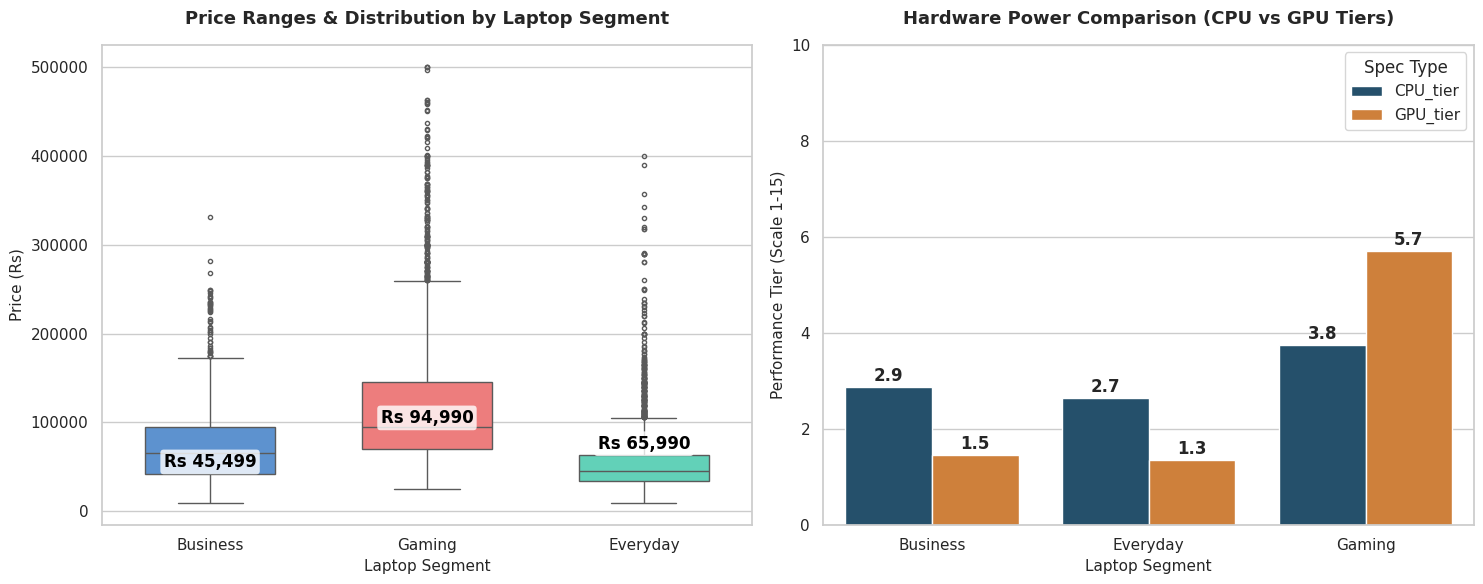

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Map laptop classes to clear descriptive names
category_map = {0: "Everyday", 1: "Gaming", 2: "Business"}
df_plot = df.copy()
df_plot["Laptop Segment"] = df_plot["laptop_class"].map(category_map)

# Set a clean, minimalist style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Box Plot of Price Distributions by Segment
sns.boxplot(
    x="Laptop Segment",
    y="Price",
    data=df_plot,
    palette=["#4A90E2", "#FF6B6B", "#50E3C2"],
    ax=axes[0],
    fliersize=3,
    width=0.6
)
axes[0].set_title("Price Ranges & Distribution by Laptop Segment", fontsize=13, fontweight="bold", pad=15)
axes[0].set_xlabel("Laptop Segment", fontsize=11)
axes[0].set_ylabel("Price (Rs)", fontsize=11)

# Annotate median prices on top of the boxes for clear reading
for i, segment in enumerate(["Everyday", "Gaming", "Business"]):
    median_val = df_plot[df_plot["Laptop Segment"] == segment]["Price"].median()
    if not np.isnan(median_val):
        axes[0].text(
            i,
            median_val,
            f"Rs {int(median_val):,}",
            ha='center',
            va='bottom',
            fontweight='bold',
            color='black',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.2')
        )

# Chart 2: Average GPU Tier vs Average CPU Tier per Segment
spec_summary = df_plot.groupby("Laptop Segment")[["CPU_tier", "GPU_tier"]].mean().reset_index()
spec_melted = spec_summary.melt(id_vars="Laptop Segment", value_vars=["CPU_tier", "GPU_tier"], var_name="Spec Type", value_name="Average Tier")

sns.barplot(
    x="Laptop Segment",
    y="Average Tier",
    hue="Spec Type",
    data=spec_melted,
    palette=["#1A5276", "#E67E22"],
    ax=axes[1]
)
axes[1].set_title("Hardware Power Comparison (CPU vs GPU Tiers)", fontsize=13, fontweight="bold", pad=15)
axes[1].set_xlabel("Laptop Segment", fontsize=11)
axes[1].set_ylabel("Performance Tier (Scale 1-15)", fontsize=11)
axes[1].set_ylim(0, 10)

# Annotate exact bar heights
for p in axes[1].patches:
    if p.get_height() > 0:
        axes[1].annotate(
            f"{p.get_height():.1f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 8),
            textcoords='offset points',
            fontweight='bold'
        )

plt.tight_layout()
plt.show()

### 📊 Simple & Easy-to-Understand Market Visualizations
Below are two very straightforward charts showing average prices and stock availability in simple, clean bar graphs.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average price for each simple group name
category_map = {0: "Everyday Laptops", 1: "Gaming Laptops", 2: "Business Laptops"}
df_simple = df.copy()
df_simple["Laptop Type"] = df_simple["laptop_class"].map(category_map)

price_summary = df_simple.groupby("Laptop Type")["Price"].mean().reset_index()

# Set up a clean, simple plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Average Price by Laptop Type
sns.barplot(
    x="Laptop Type",
    y="Price",
    data=price_summary,
    palette=["#4A90E2", "#FF6B6B", "#50E3C2"],
    ax=axes[0]
)
axes[0].set_title("How Much Do Different Laptop Types Cost on Average?", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Laptop Type", fontsize=10)
axes[0].set_ylabel("Average Price (Rs)", fontsize=10)
for p in axes[0].patches:
    axes[0].annotate(f"Rs {int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

# Chart 2: Availability (In Stock vs. Out of Stock)
stock_counts = df["market_status"].value_counts().reset_index()
stock_counts.columns = ["Status", "Count"]
stock_counts["Status"] = stock_counts["Status"].map({"Available": "Yes (In Stock)", "Out of Stock": "No (Sold Out)"})

sns.barplot(
    x="Status",
    y="Count",
    data=stock_counts,
    palette=["#2ECC71", "#95A5A6"],
    ax=axes[1]
)
axes[1].set_title("Are the Laptops Ready to Buy?", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Available in Store?", fontsize=10)
axes[1].set_ylabel("Number of Laptops", fontsize=10)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

### 🖥️ Gradio Web Application
Below is the complete, interactive web interface running directly inside your notebook. Use the tabs to classify custom specs, obtain budget-friendly laptop recommendations, and explore key dataset insights.

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Save pipeline components
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(best_model, 'model.pkl')

# Load components
scaler_loaded = joblib.load('scaler.pkl')
model_loaded = joblib.load('model.pkl')

features_list = [
    "RAM",
    "SSD",
    "HDD",
    "VRAM",
    "Screen",
    "Weight",
    "Thickness",
    "Refresh",
    "GPU_tier",
    "CPU_tier",
]

# Extract unique RAM values and strictly remove non-standard 2, 3, 6, 18, 36, and 48 GB options
raw_ram = sorted([int(x) for x in df["RAM"].dropna().unique() if x > 0])
raw_ram = [x for x in raw_ram if x not in [2, 3, 6, 18, 36, 48]]
choice_ram = [(f"{x} GB", x) for x in raw_ram]

# Filter SSD: Start from 256 GB and remove 360 GB
raw_ssd = sorted([int(x) for x in df["SSD"].dropna().unique() if x >= 256])
raw_ssd = [x for x in raw_ssd if x != 360]
choice_ssd = [
    (f"{x/1024:.1f} TB" if x >= 1024 else f"{x} GB", x) for x in raw_ssd
]

# Filter HDD: Start from 256 GB and remove 360 GB (if present)
raw_hdd = sorted([int(x) for x in df["HDD"].dropna().unique() if x >= 256])
raw_hdd = [x for x in raw_hdd if x != 360]
choice_hdd = [
    (f"{x/1024:.1f} TB" if x >= 1024 else f"{x} GB", x) for x in raw_hdd
]

# Filter VRAM: Start from 4 GB and remove 10 GB
raw_vram = sorted([int(x) for x in df["VRAM"].dropna().unique() if x >= 4])
raw_vram = [x for x in raw_vram if x != 10]
choice_vram = [(f"{x} GB", x) for x in raw_vram]

# Set Refresh Rate to strictly defined common choices: 60, 90, 120, 144, 240, 360, 480
raw_refresh = [60, 90, 120, 144, 240, 360, 480]
choice_refresh = [(f"{x} Hz", x) for x in raw_refresh]

raw_screen = sorted([float(x) for x in df["Screen"].dropna().unique() if x > 0])
choice_screen = [(f"{x} Inches", x) for x in raw_screen]


def classify_interface(
    ram, ssd, hdd, vram, screen, weight, thickness, refresh, gpu_t, cpu_t
):
    row = pd.DataFrame(
        [[ram, ssd, hdd, vram, screen, weight, thickness, refresh, gpu_t, cpu_t]],
        columns=features_list,
    )
    row_scaled = scaler_loaded.transform(row)
    pred = int(model_loaded.predict(row_scaled)[0])
    probs = model_loaded.predict_proba(row_scaled)[0]

    labels = ["Everyday Laptop", "Gaming Laptop", "Business Laptop"]
    result_label = labels[pred]

    prob_text = f"Everyday: {probs[0]*100:.1f}% | Gaming: {probs[1]*100:.1f}% | Business: {probs[2]*100:.1f}%"
    return f"### Result: {result_label}\n\n**Class Probabilities:**\n{prob_text}"


def recommend_interface(min_p, max_p, need, top_n):
    recs = recommend(min_p, max_p, need.lower(), top_n)
    if recs.empty:
        return "No available laptops match these budget limits."
    return recs


def generate_visualizations():
    category_map = {0: "Everyday", 1: "Gaming", 2: "Business"}
    df_plot = df.copy()
    df_plot["Laptop Segment"] = df_plot["laptop_class"].map(category_map)

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    price_summary = (
        df_plot.groupby("Laptop Segment")["Price"].mean().reset_index()
    )
    sns.barplot(
        x="Laptop Segment",
        y="Price",
        data=price_summary,
        palette=["#4A90E2", "#FF6B6B", "#50E3C2"],
        order=["Everyday", "Gaming", "Business"],
        ax=axes[0],
    )
    axes[0].set_title(
        "Average Price by Laptop Segment",
        fontsize=12,
        fontweight="bold",
        pad=12,
    )
    axes[0].set_xlabel("Laptop Segment", fontsize=10)
    axes[0].set_ylabel("Average Price (Rs)", fontsize=10)
    for p in axes[0].patches:
        if p.get_height() > 0:
            axes[0].annotate(
                f"Rs {int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2.0, p.get_height()),
                ha="center",
                va="center",
                xytext=(0, 8),
                textcoords="offset points",
                fontweight="bold",
            )

    spec_summary = (
        df_plot.groupby("Laptop Segment")[["CPU_tier", "GPU_tier"]
    ]
        .mean()
        .reset_index()
    )
    spec_melted = spec_summary.melt(
        id_vars="Laptop Segment",
        value_vars=["CPU_tier", "GPU_tier"],
        var_name="Spec Type",
        value_name="Average Tier",
    )

    sns.barplot(
        x="Laptop Segment",
        y="Average Tier",
        hue="Spec Type",
        data=spec_melted,
        palette=["#1A5276", "#E67E22"],
        order=["Everyday", "Gaming", "Business"],
        ax=axes[1],
    )
    axes[1].set_title(
        "Hardware Power Comparison (CPU vs GPU Tiers)",
        fontsize=12,
        fontweight="bold",
        pad=12,
    )
    axes[1].set_xlabel("Laptop Segment", fontsize=10)
    axes[1].set_ylabel("Performance Tier (Scale 1-15)", fontsize=10)
    axes[1].set_ylim(0, 10)
    for p in axes[1].patches:
        if p.get_height() > 0:
            axes[1].annotate(
                f"{p.get_height():.1f}",
                (p.get_x() + p.get_width() / 2.0, p.get_height()),
                ha="center",
                va="center",
                xytext=(0, 8),
                textcoords="offset points",
                fontweight="bold",
            )

    plt.tight_layout()
    return fig


with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 💻 Smart Laptop Hub: Classification & Recommendations")

    with gr.Tab("🔍 Spec Classifier"):
        gr.Markdown(
            "Input custom laptop features to determine if it falls under **Everyday**, **Gaming**, or **Business** categories."
        )
        with gr.Row():
            with gr.Column():
                in_ram = gr.Dropdown(
                    choices=choice_ram,
                    value=8 if 8 in raw_ram else (raw_ram[0] if raw_ram else None),
                    label="RAM",
                    allow_custom_value=False,
                )
                in_ssd = gr.Dropdown(
                    choices=choice_ssd,
                    value=raw_ssd[0] if raw_ssd else None,
                    label="SSD",
                    allow_custom_value=False,
                )
                in_hdd = gr.Dropdown(
                    choices=choice_hdd,
                    value=raw_hdd[0] if raw_hdd else None,
                    label="HDD",
                    allow_custom_value=False,
                )
                in_vram = gr.Dropdown(
                    choices=choice_vram,
                    value=raw_vram[0] if raw_vram else None,
                    label="VRAM",
                    allow_custom_value=False,
                )
                in_refresh = gr.Dropdown(
                    choices=choice_refresh,
                    value=60,
                    label="Refresh Rate",
                    allow_custom_value=False,
                )
            with gr.Column():
                in_screen = gr.Dropdown(
                    choices=choice_screen,
                    value=raw_screen[0] if raw_screen else None,
                    label="Screen Size",
                    allow_custom_value=False,
                )
                in_weight = gr.Slider(
                    minimum=0.5,
                    maximum=5.0,
                    value=1.7,
                    step=0.05,
                    label="Weight (Kg)",
                )
                in_thickness = gr.Slider(
                    minimum=5.0,
                    maximum=40.0,
                    value=18.0,
                    step=0.5,
                    label="Thickness (mm)",
                )
                in_gpu = gr.Slider(
                    minimum=1.0,
                    maximum=15.0,
                    value=2.0,
                    step=0.5,
                    label="GPU Power Tier (1-15)",
                )
                in_cpu = gr.Slider(
                    minimum=1.0,
                    maximum=5.0,
                    value=3.0,
                    step=1.0,
                    label="CPU Power Tier (1-5)",
                )

        btn_classify = gr.Button(
            "Classify Laptop Spec Profile", variant="primary"
        )
        out_txt = gr.Markdown(label="Classification Outcome")
        btn_classify.click(
            classify_interface,
            inputs=[
                in_ram,
                in_ssd,
                in_hdd,
                in_vram,
                in_screen,
                in_weight,
                in_thickness,
                in_refresh,
                in_gpu,
                in_cpu,
            ],
            outputs=out_txt,
        )

    with gr.Tab("🎯 Live Matchmaker & Recommendations"):
        gr.Markdown(
            "Find ready-to-buy laptops in stock matching your desired segment and price range."
        )
        with gr.Row():
            in_min = gr.Number(value=40000, label="Minimum Budget (Rs)")
            in_max = gr.Number(value=90000, label="Maximum Budget (Rs)")
            in_need = gr.Dropdown(
                choices=["Gaming", "Everyday"],
                value="Everyday",
                label="Usage Focus",
                allow_custom_value=False,

            )
            in_top = gr.Slider(
                minimum=1, maximum=10, value=5, step=1, label="Laptops to Show"
            )

        btn_recom = gr.Button("Find Matches", variant="primary")
        out_df = gr.Dataframe(label="Top Matches")
        btn_recom.click(
            recommend_interface,
            inputs=[in_min, in_max, in_need, in_top],
            outputs=out_df,
        )

    with gr.Tab("📊 Market Insights"):
        gr.Markdown(
            "Explore simple, live price and hardware spec distributions directly compiled across all three segments."
        )
        btn_insights = gr.Button(
            "Generate Market Insights Plots", variant="primary"
        )
        out_plot = gr.Plot(label="Market Distribution Analytics")
        btn_insights.click(generate_visualizations, inputs=[], outputs=out_plot)

demo.launch(share=True, debug=False)